# Lab 1 plots

## Load data


In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

folder = Path.cwd()  # Read the CSV files from the notebook folder.
output = folder / "notebook_plots"
output.mkdir(exist_ok=True)  # Save all generated images in this folder.
# Use the same motion order in every row of plots.
motions = ["circle", "spiral", "line"]
titles = ["Circle", "Spiral", "Accelerated line"]

def read_data(sensor, motion):
    # Read the three sensor values and timestamp from each CSV row.
    with open(folder / f"{sensor}_content_{motion}.csv", newline="") as file:
        rows = list(csv.reader(file))[1:]  # Skip the header row; keep all measurement rows.
    values = []
    time = []
    first = int(rows[0][-1])  # First timestamp in this recording.
    for row in rows:
        values.append([float(row[0]), float(row[1]), float(row[2])])
        # Subtract the first timestamp and convert nanoseconds to seconds.
        time.append((int(row[-1]) - first) / 1e9)
    return time, np.array(values)

odom = [read_data("odom", motion) for motion in motions]  # x, y, theta
imu = [read_data("imu", motion) for motion in motions]    # ax, ay, omega z


## Trajectory


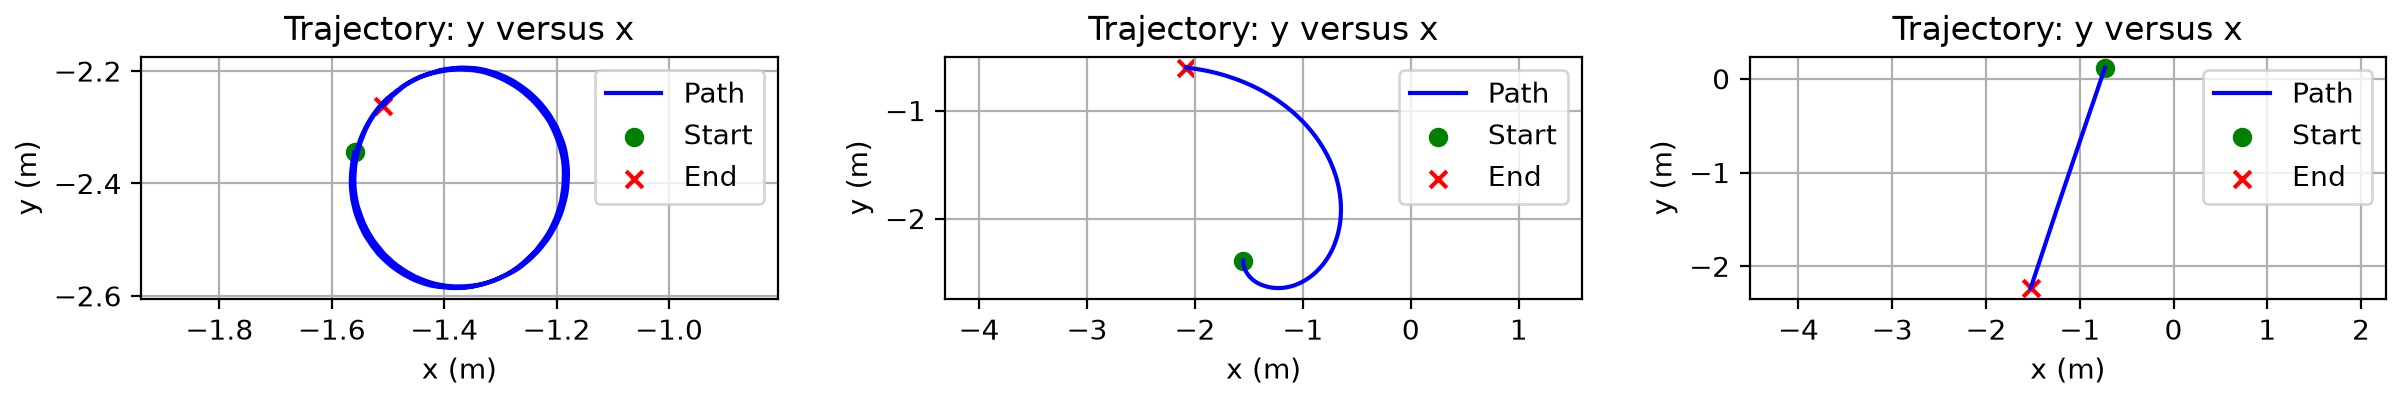

In [2]:
# Create one plot for each motion.
fig, axes = plt.subplots(1, 3, figsize=(12, 2))
for ax, (time, data) in zip(axes, odom):
    x = data[:, 0]  # Select the x position from every odometry sample.
    y = data[:, 1]
    ax.plot(x, y, label="Path", color="blue")
    # Mark the first and last recorded positions on the path.
    ax.scatter(x[0], y[0], marker="o", color="green", label="Start")
    ax.scatter(x[-1], y[-1], marker="x", color="red", label="End")
    ax.set(title="Trajectory: y versus x", xlabel="x (m)", ylabel="y (m)")
    # Use equal scales so the path shape is not stretched.
    ax.axis("equal")
    ax.legend()
    ax.grid(True)
# Adjust spacing so titles and axis labels fit.
fig.tight_layout(pad=0.5)
# Save this row before combining it with the others.
fig.savefig(output / "01_trajectory.png", dpi=200)
plt.show()


## Position vs time


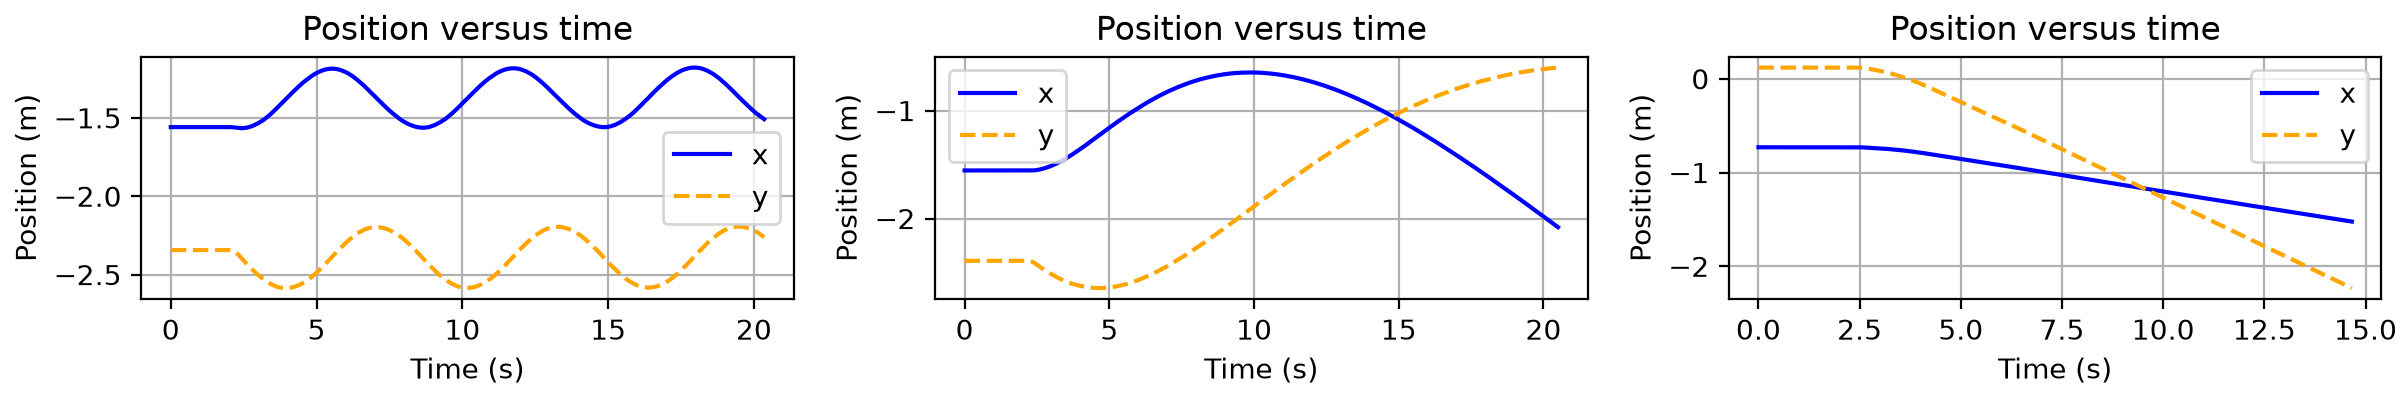

In [3]:
# Create one plot for each motion.
fig, axes = plt.subplots(1, 3, figsize=(12, 2))
for ax, (time, data) in zip(axes, odom):
    # Plot both position columns against the odometry timestamps.
    x = data[:, 0]
    y = data[:, 1]
    ax.plot(time, x, label="x", color="blue")
    ax.plot(time, y, label="y", color="orange", linestyle="--")
    ax.set(title="Position versus time", xlabel="Time (s)", ylabel="Position (m)")
    ax.legend()
    ax.grid(True)
# Adjust spacing so titles and axis labels fit.
fig.tight_layout(pad=0.5)
# Save this row before combining it with the others.
fig.savefig(output / "02_position.png", dpi=200)
plt.show()


## Theta vs time


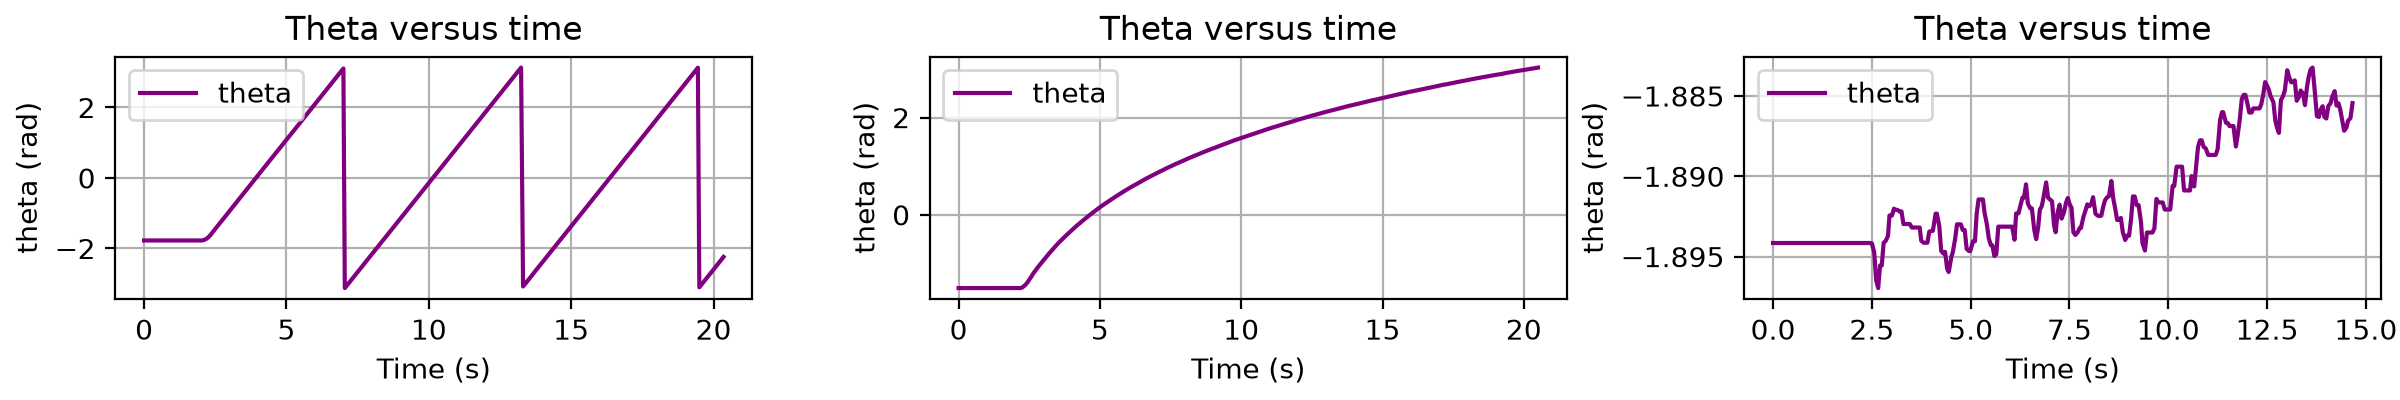

In [4]:
# Create one plot for each motion.
fig, axes = plt.subplots(1, 3, figsize=(12, 2))
for ax, (time, data) in zip(axes, odom):
    theta = data[:, 2]  # Third odometry column: theta in radians.
    ax.plot(time, theta, label="theta", color="purple")
    ax.set(title="Theta versus time", xlabel="Time (s)", ylabel="theta (rad)")
    ax.legend()
    ax.grid(True)
# Adjust spacing so titles and axis labels fit.
fig.tight_layout(pad=0.5)
# Save this row before combining it with the others.
fig.savefig(output / "03_theta.png", dpi=200)
plt.show()


## Acceleration vs time


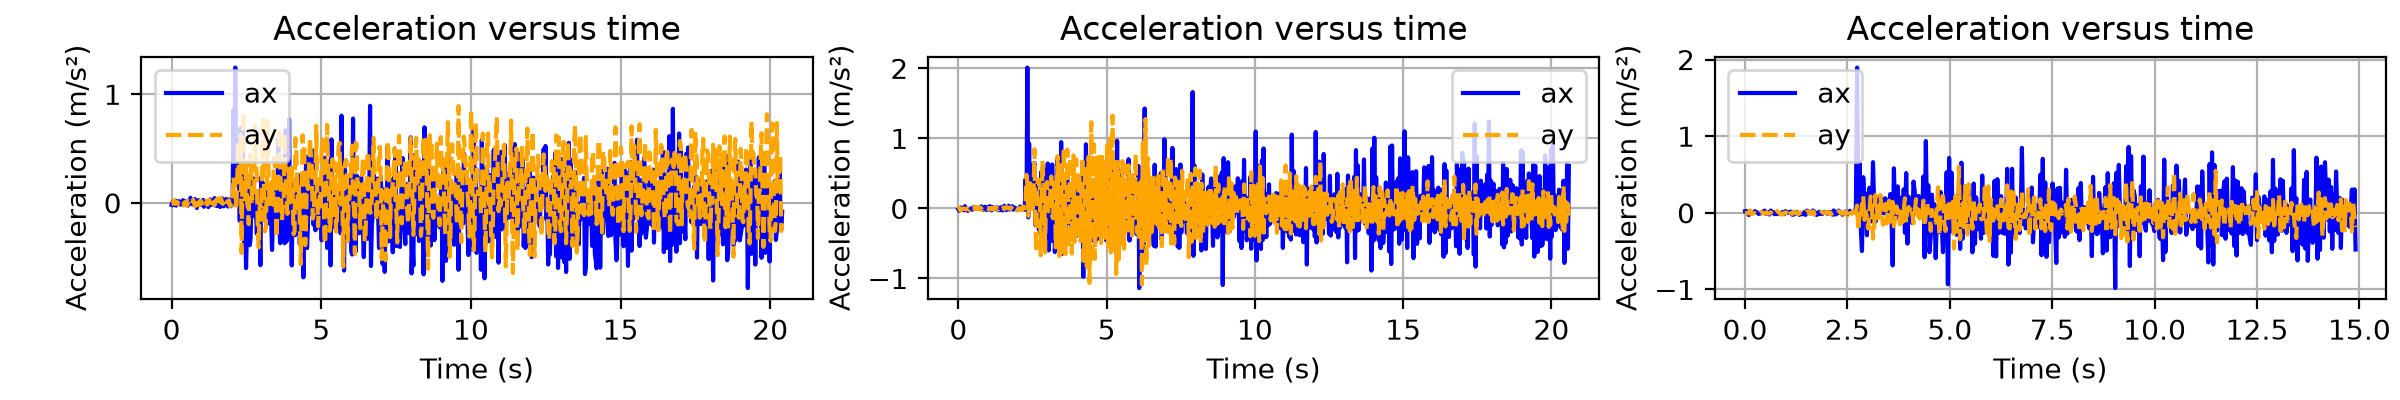

In [5]:
# Create one plot for each motion.
fig, axes = plt.subplots(1, 3, figsize=(12, 2))
for ax, (time, data) in zip(axes, imu):
    # First two IMU columns: x and y acceleration in m/s².
    ax.plot(time, data[:, 0], label="ax", color="blue")
    ax.plot(time, data[:, 1], label="ay", color="orange", linestyle="--")
    ax.set(title="Acceleration versus time", xlabel="Time (s)", ylabel="Acceleration (m/s²)")
    ax.legend()
    ax.grid(True)
# Adjust spacing so titles and axis labels fit.
fig.tight_layout(pad=0.5)
# Save this row before combining it with the others.
fig.savefig(output / "04_acceleration.png", dpi=200)
plt.show()


## Angular velocity vs time


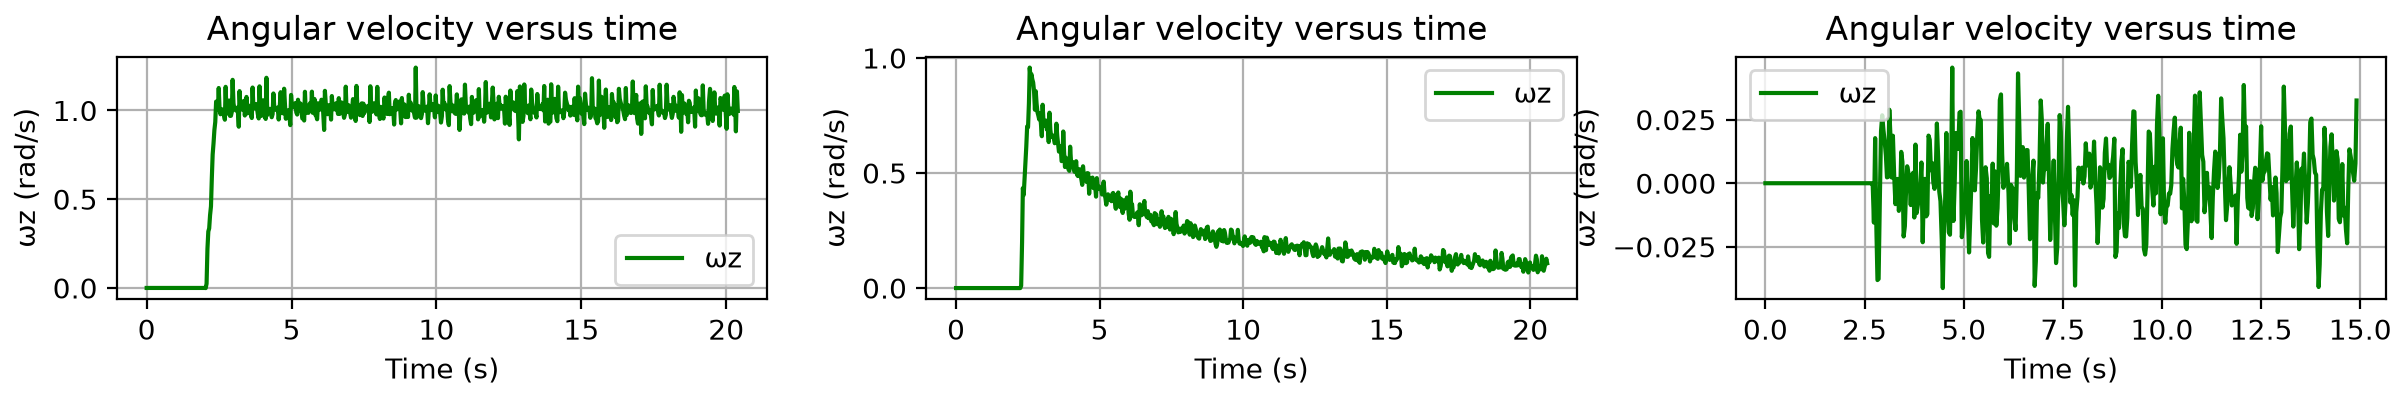

In [6]:
# Create one plot for each motion.
fig, axes = plt.subplots(1, 3, figsize=(12, 2))
for ax, (time, data) in zip(axes, imu):
    # Third IMU column: angular velocity around z in rad/s.
    ax.plot(time, data[:, 2], label="ωz", color="green")
    ax.set(title="Angular velocity versus time", xlabel="Time (s)", ylabel="ωz (rad/s)")
    ax.legend()
    ax.grid(True)
# Adjust spacing so titles and axis labels fit.
fig.tight_layout(pad=0.5)
# Save this row before combining it with the others.
fig.savefig(output / "05_angular_velocity.png", dpi=200)
plt.show()


## Combine plots


Saved: C:\Users\neeln\Documents\544\Lab 1\notebook_plots\lab1_combined.png


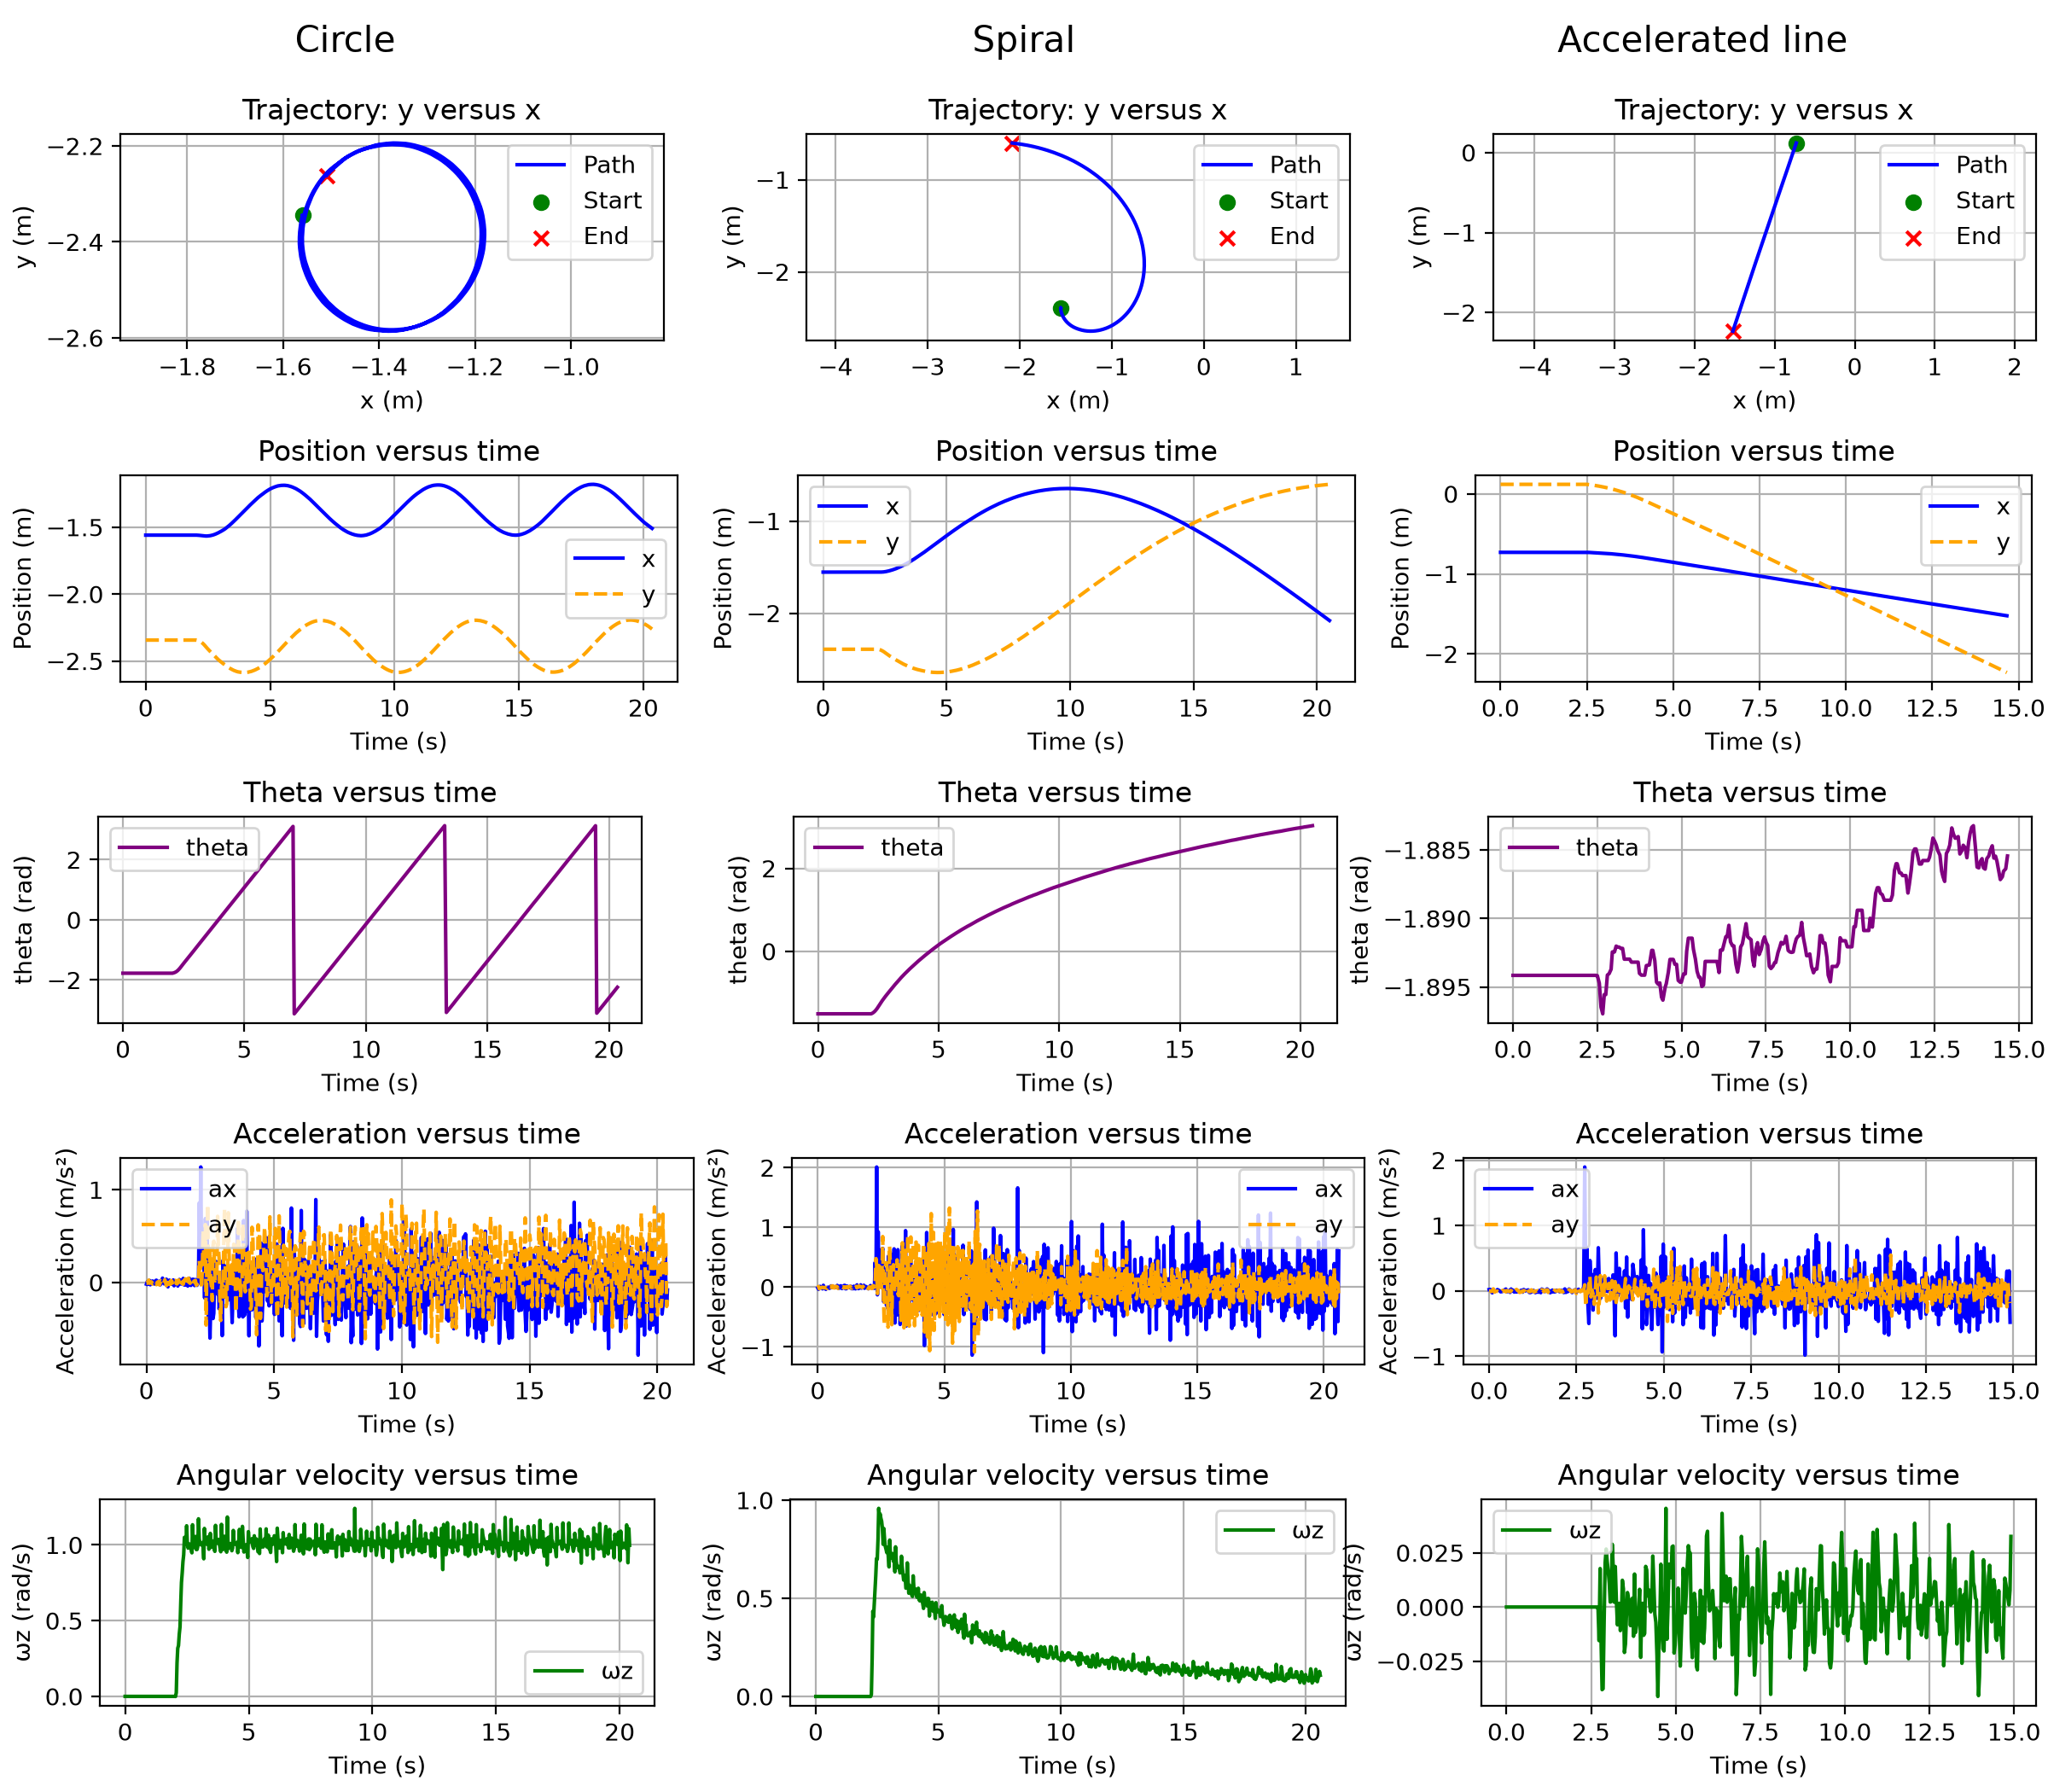

In [7]:
# Add one motion heading above each column of the final image.
header_fig, headings = plt.subplots(1, 3, figsize=(12, 0.5))
for ax, title in zip(headings, titles):
    ax.text(0.5, 0.5, title, ha="center", va="center", fontsize=15)
    ax.axis("off")  # Hide axes for the heading row.
header_fig.tight_layout(pad=0.5)
header_fig.savefig(output / "column_headings.png", dpi=200)
plt.close(header_fig)

files = ["column_headings.png", "01_trajectory.png", "02_position.png", "03_theta.png",
         "04_acceleration.png", "05_angular_velocity.png"]
images = [Image.open(output / name).convert("RGB") for name in files]
# Make a canvas with the same width and the total height of all images.
combined = Image.new("RGB", (images[0].width, sum(im.height for im in images)), "white")
top = 0
for image in images:
    combined.paste(image, (0, top))
    top += image.height  # Move down by the height of the image just added.
# Save the combined image for the report.
combined.save(output / "lab1_combined.png")
print("Saved:", output / "lab1_combined.png")
display(combined)


## Laser scans


Circle: row 78, time 10.10 s, 485 valid beams
Spiral: row 78, time 10.08 s, 408 valid beams
Accelerated line: row 78, time 10.11 s, 467 valid beams


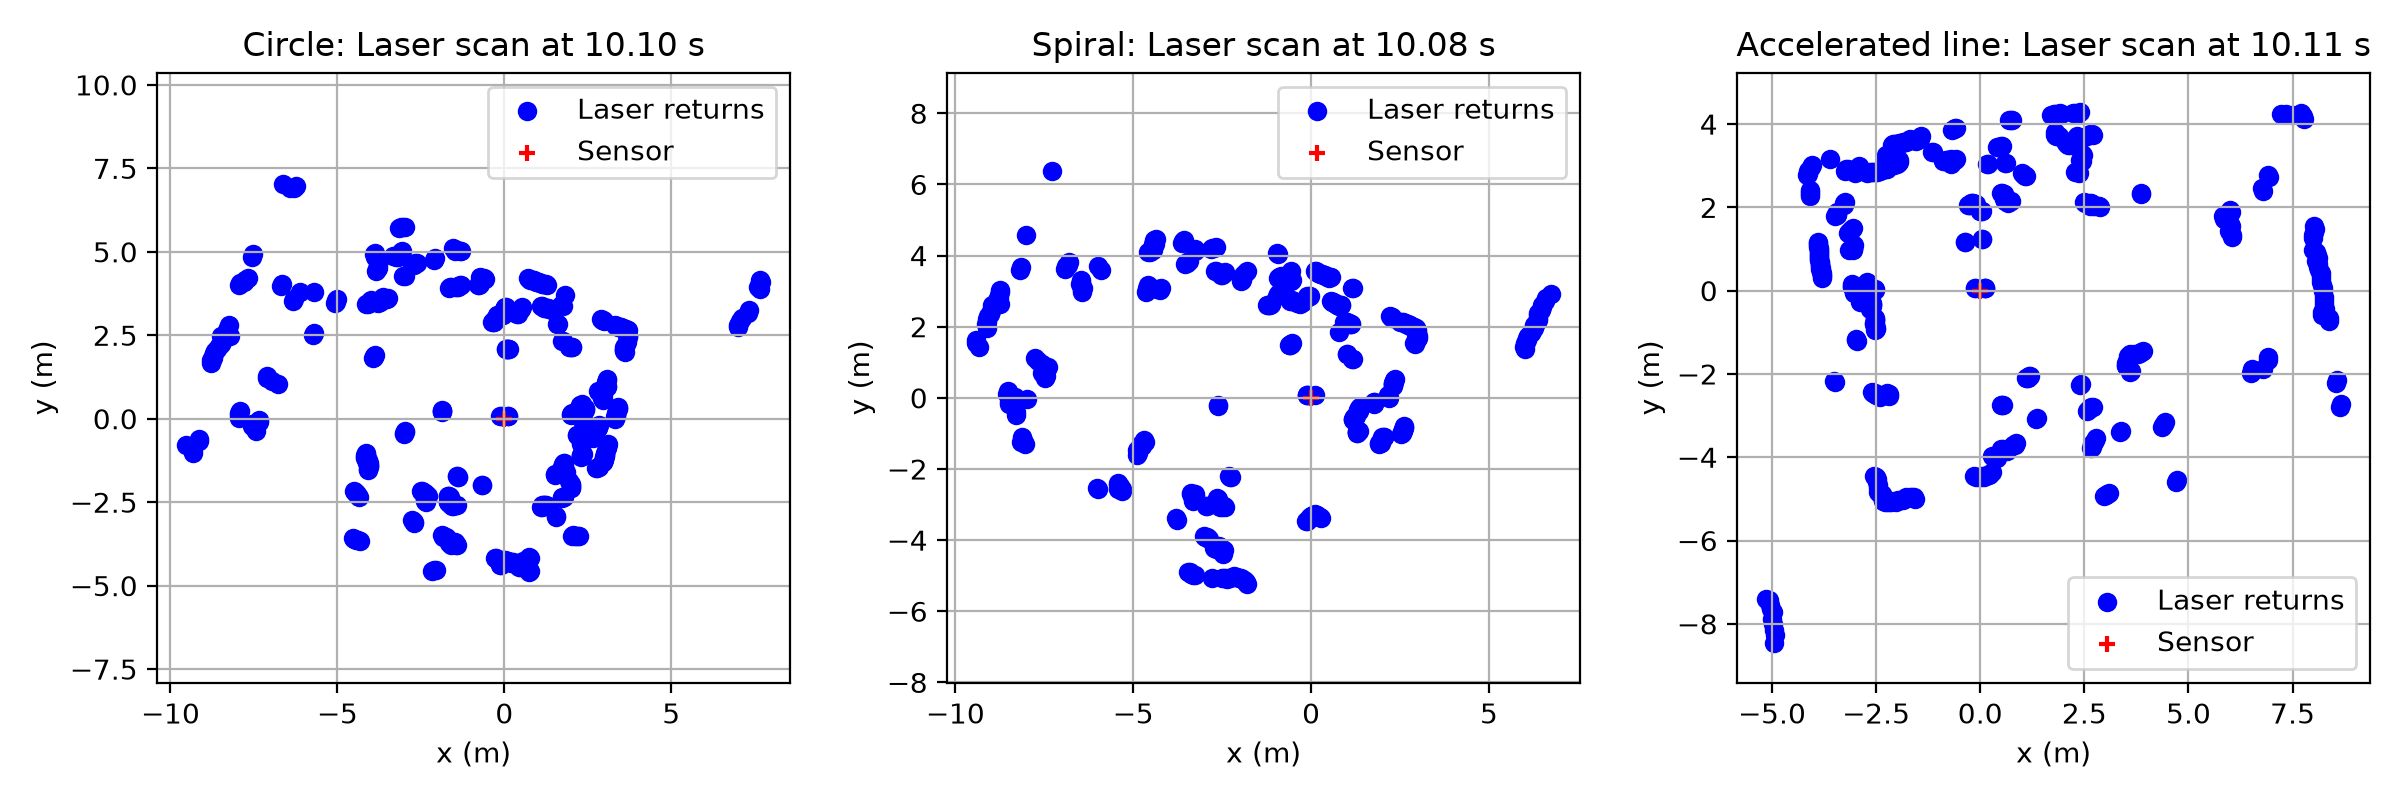

In [ ]:
# One scan from each motion, shown side by side.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, motion, title in zip(axes, motions, titles):
    with open(folder / f"laser_content_{motion}.csv", newline="") as file:
        rows = list(csv.reader(file))[1:]  # Skip the header.

    # Convert scan timestamps to seconds from the first scan in this file.
    first = int(rows[0][-1])
    times = [(int(row[-1]) - first) / 1e9 for row in rows]

    # Use the first scan recorded at or after 10 seconds.
    for index, time in enumerate(times):
        if time >= 10:
            break
    scan = rows[index]

    # The first CSV field contains the full list of ranges.
    ranges = [float(value) for value in scan[0].strip("[]").split(",")]
    angle_increment = float(scan[1])
    x, y = [], []
    for i, r in enumerate(ranges):
        # Ignore infinity, NaN and nonpositive ranges; keep the original beam index.
        if not np.isfinite(r) or r <= 0:
            continue
        # angle_min was not recorded, so the first beam is taken as zero angle.
        theta = i * angle_increment
        # Convert range and angle to Cartesian coordinates: x = r cos(theta), y = r sin(theta).
        x.append(r * np.cos(theta))
        y.append(r * np.sin(theta))

    ax.scatter(x, y, color="blue", label="LiDAR Measurements")
    ax.scatter(0, 0, color="red", marker="+", label="Sensor")
    ax.set_title(f"{title}: Laser scan at {times[index]:.2f} s")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.axis("equal")  # Same scale on both axes.
    ax.legend()
    ax.grid(True)
    print(f"{title}: row {index + 1}, time {times[index]:.2f} s, {len(x)} valid beams")

fig.tight_layout()
fig.savefig(output / "laser_scans.png", dpi=200)  # Save the three scans together.
plt.show()


## Saved map


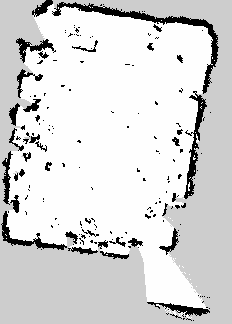

In [9]:
# Save the map as a PNG for the report.
map_image = Image.open(folder / "map_data" / "map.pgm")
map_image.save(output / "map.png")
display(map_image)
